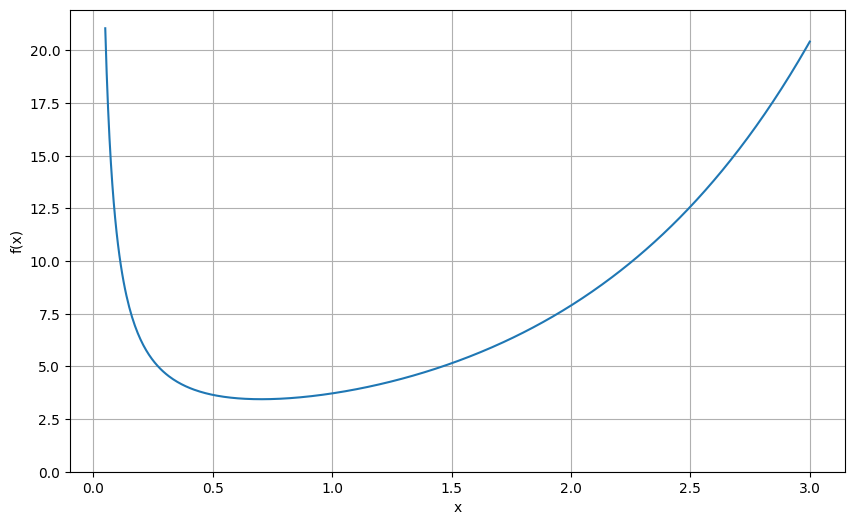

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Define the function f(x) = 1/x + e^x
def f(x):
    return 1/x + np.exp(x)

# Generate x values for x > 0. Avoid x=0 to prevent division by zero.
x_values = np.linspace(0.05, 3, 500) # Start from a small positive number
y_values = f(x_values)

# Plot the function
plt.figure(figsize=(10, 6))
plt.plot(x_values, y_values)
plt.xlabel('x')
plt.ylabel('f(x)')
plt.grid(True)
#plt.legend()
plt.ylim(bottom=0) # Ensure y-axis starts at 0 or above
plt.show()

In [13]:
## Las iteraciones
max_iter = 20
tol = 10e-10 # tolerancia

## encontramos el minimo de f usando gradient descent
## note que si f: R -> R es facil
def grad(x):
   return -1/x**2 + np.exp(x)

def armijo(xn, grad, max_backtracks=100):
  alpha = 1.0
  beta = 0.85
  c = 0.55
  count = 0 # sentinela

  # Buscamos un alpha que cumpla la condición de Armijo y asegure que x permanezca en el dominio positivo (x > 0)
  while count < max_backtracks: # asegura que no hay infinite loop
    candidate = xn + alpha * grad
    if candidate > 0:
      if f(xn) - f(candidate) >= c * alpha:
        break
    alpha = beta * alpha # contraccion de alpha
    count += 1
  return alpha


## The iteration of the gradiente descent method is: x_n+1 <- x_n - t * grad(x_n)
x_n = 2.5 # initial guess
iterations_dg = [x_n]
k = 0
error_sucesivo = 1.0
while k < max_iter and error_sucesivo > tol:
  x_pre = x_n # x_pre es temporal
  # La dirección de descenso es -grad(x_n)
  t = armijo(x_n, -grad(x_n))
  x_n = x_n - t * grad(x_n)   # actualizamos la variable x_n con un valor mejor
  error_sucesivo = abs(x_n - x_pre)
  iterations_dg.append(float(x_n))
  k += 1
print(f"El metodo del descenso por gradiente termino en {k} pasos")

## ahora vamos con Newton
def hessian(x):
  return 2/x**3 + np.exp(x)

## The newton iteration is given by x_n+1 <- x_n - 1 f'(x_n)/f''(x_n)
x_n = 2.5
iterations_newton = [x_n]
k = 0
# Para guardar |x_n+1 - x_n|
error_sucesivo = 1.0
while k < max_iter and error_sucesivo > tol:
  x_pre = x_n
  x_n = x_n - grad(x_n)/hessian(x_n)
  error_sucesivo = abs(x_n - x_pre)
  iterations_newton.append(float(x_n))
  k += 1
print(f"El metodo de Newton termino en {k} pasos")

#print("Iteraciones DG:", iterations_dg)

El metodo del descenso por gradiente termino en 20 pasos
El metodo de Newton termino en 6 pasos


In [4]:
import pandas as pd

# The exact minimum value from the Newton's method which converges faster
exact_min = 0.7034674224983917

# recortar iterations_dg a la long de newton
iterations_dg = iterations_dg[:len(iterations_newton)]
# Create a DataFrame to compare the iterations
data = {
    'Iteration': range(len(iterations_dg)),
    'Gradient Descent (x_n)': iterations_dg,
    'GD Error (abs diff)': [abs(x - exact_min) for x in iterations_dg],
    'Newton\'s Method (x_n)': iterations_newton,
    'Newton Error (abs diff)': [abs(x - exact_min) for x in iterations_newton]
}

df_comparison = pd.DataFrame(data)

# Display the comparison table
display(df_comparison)

,Iteration,Gradient Descent (x_n),GD Error (abs diff),Newton's Method (x_n),Newton Error (abs diff)
0,0,2.500000,1.796533,2.500000,1.796533e+00
1,1,0.133079,0.570389,1.523395,8.199273e-01
2,2,1.955733,1.252266,0.716780,1.331248e-02
3,3,0.378965,0.324503,0.703215,2.519908e-04
4,4,1.044225,0.340758,0.703467,9.193564e-08
5,5,0.519924,0.183543,0.703467,1.221245e-14
6,6,0.806883,0.103416,0.703467,0.000000e+00


### Definicion
Un punto fijo de una funcion $f$ es un punto tal que $f(x) = x$.

Para una iteracion $x_{n+1} = x_n + F(x_n)$, un punto fijo es un punto $x^*$ tal que:
$$x^* = x^* + F(x^*)$$

### Cosas que podemos hacer
1) adaptar los metodos para funciones $f:\ \mathbb{R}^n \to \mathbb{R}$.
2) implementar el metodo de Armijo. (long. de paso mejorada)
3) pasar a usar las librerias. (Aprender a usar el API)


Visualización comparativa de dos reglas para elegir la longitud de paso
en un método iterativo de optimización:

1. Regla de Armijo con backtracking (descenso suficiente).
2. Longitud de paso exacta (búsqueda exacta sobre la dirección).

Problema utilizado:  
$$f(x) = 1/2 x^T Q x$$

con Q definida positiva. Para este problema la búsqueda exacta a lo largo
de una dirección de descenso tiene solución cerrada:  

$$\alpha^* = -(\nabla f(x)^T d) / (d^T Q d)$$

Idea central de la comparación: Armijo NO calcula el minimizador de
phi(alpha) = f(x + alpha d); únicamente garantiza una disminución
suficiente. La búsqueda exacta sí minimiza phi, y por eso da pasos más
cortos (salvo que la trayectoria inicial coincida) pero no necesita
evaluar la función un número arbitrario de veces.


In [14]:
# ---------------------------------------------------------------------------
# Problema de optimización
# ---------------------------------------------------------------------------

Q = np.array([
    [2.0, 0.6],
    [0.6, 1.3],
])

X0 = np.array([1.5, -1.2])

# Parámetros de la regla de Armijo.
ALPHA_INITIAL = 1.5
BETA = 0.5
C1 = 1.0e-4
MAX_BACKTRACKS = 40

# Criterios de parada.
MAX_ITERATIONS = 25
GRADIENT_TOLERANCE = 1.0e-10
STEP_TOLERANCE = 1.0e-10

# Colores.
COLOR_ARMIJO = "#E76F00"
COLOR_EXACT = "#1565C0"
COLOR_CURRENT = "#C62828"
COLOR_OPTIMUM = "#2E7D32"
COLOR_GRID = "#D5D8DC"

In [15]:
# ---------------------------------------------------------------------------
# Funciones del problema
# ---------------------------------------------------------------------------

def objective(x: np.ndarray) -> float:
    """Valor de f(x) = 1/2 x^T Q x."""
    x = np.asarray(x, dtype=float)
    return float(0.5 * x @ Q @ x)


def gradient(x: np.ndarray) -> np.ndarray:
    """Gradiente de f. grad f = Qx"""
    return Q @ np.asarray(x, dtype=float)

def line_objective(
    x: np.ndarray,
    direction: np.ndarray,
    alpha: np.ndarray,
) -> np.ndarray:
    """
    Evalúa la función objetivo sobre la recta de búsqueda:

        phi(alpha) = f(x + alpha * direction)

    Acepta alpha escalar o vector y devuelve un vector de valores.
    """
    alpha = np.atleast_1d(np.asarray(alpha, dtype=float))
    points = x[None, :] + alpha[:, None] * direction[None, :]
    return 0.5 * np.einsum("bi,ij,bj->b", points, Q, points)


In [19]:
# ---------------------------------------------------------------------------
# Reglas de elección de paso
# ---------------------------------------------------------------------------

def armijo_backtracking(
    x: np.ndarray,
    direction: np.ndarray,
    alpha_initial: float = ALPHA_INITIAL,
    beta: float = BETA,
    c1: float = C1,
    max_backtracks: int = MAX_BACKTRACKS,
) -> tuple[float, list[float]]:
    """
    Encuentra alpha por backtracking usando la regla de Armijo:

        f(x + alpha d) <= f(x) + c1 * alpha * grad f(x)^T d

    Se prueban alpha_0, beta*alpha_0, beta^2*alpha_0, ... y se acepta el
    primer valor que satisface la desigualdad.

    Devuelve:
        alpha_armijo : paso aceptado
        tested       : lista de pasos examinados, en orden

    Se exige que direction sea una dirección de descenso.
    """
    x = np.asarray(x, dtype=float)
    direction = np.asarray(direction, dtype=float)

    f_x = objective(x)
    directional_derivative = float(gradient(x) @ direction)

    if directional_derivative >= 0:
        raise ValueError("La dirección no es de descenso.")

    alpha = alpha_initial
    tested: list[float] = []

    for _ in range(max_backtracks):
        tested.append(alpha)

        f_candidate = objective(x + alpha * direction)
        armijo_bound = f_x + c1 * alpha * directional_derivative

        if f_candidate <= armijo_bound:
            return alpha, tested

        alpha *= beta

    raise RuntimeError(
        "Backtracking agotó los intentos sin cumplir la condición de Armijo."
    )


def exact_line_search(x: np.ndarray, direction: np.ndarray) -> float:
    """
    Búsqueda exacta para f(x) = 1/2 x^T Q x.

    Se minimiza phi(alpha) = f(x + alpha d). Como

        phi'(alpha) = g^T d + alpha d^T Q d,

    el minimizador en alpha >= 0 es

        alpha_exact = -(g^T d) / (d^T Q d).
    """
    x = np.asarray(x, dtype=float)
    direction = np.asarray(direction, dtype=float)

    g = gradient(x)
    numerator = -float(g @ direction)
    denominator = float(direction @ Q @ direction)

    if denominator <= 0:
        raise ValueError("La dirección no produce una recta cuadrática válida.")

    alpha_exact = numerator / denominator

    if alpha_exact < 0:
        raise ValueError("El minimizador exacto cae fuera de alpha >= 0.")

    return alpha_exact


def run_iterations(
    method: str,
    max_iterations: int = MAX_ITERATIONS,
    alpha_initial: float = ALPHA_INITIAL,
    beta: float = BETA,
    c1: float = C1,
) -> tuple[np.ndarray, np.ndarray, list[float]]:
    """
    Ejecuta steepest descent (direccion = -grad f) usando la regla indicada.

    method = "armijo"  -> backtracking con la condición de Armijo
    method = "exact"   -> búsqueda exacta sobre la dirección

    Devuelve:
        puntos : trayectoria x_0, x_1, ...
        valores : f(x_0), f(x_1), ...
        pasos   : alpha_0, alpha_1, ...
    """
    if method not in {"armijo", "exact"}:
        raise ValueError("method debe ser 'armijo' o 'exact'.")

    x = X0.copy()
    points = [x.copy()]
    values = [objective(x)]
    steps: list[float] = []

    for _ in range(max_iterations):
        g = gradient(x)

        if np.linalg.norm(g) <= GRADIENT_TOLERANCE:
            break

        direction = -g

        if method == "armijo":
            alpha, _ = armijo_backtracking(
                x, direction,
                alpha_initial=alpha_initial,
                beta=beta,
                c1=c1,
            )
        else:
            alpha = exact_line_search(x, direction)

        x_new = x + alpha * direction

        points.append(x_new.copy())
        values.append(objective(x_new))
        steps.append(alpha)

        if np.linalg.norm(x_new - x) <= STEP_TOLERANCE * (
            1.0 + np.linalg.norm(x)
        ):
            break

        x = x_new

    return np.asarray(points), np.asarray(values), steps


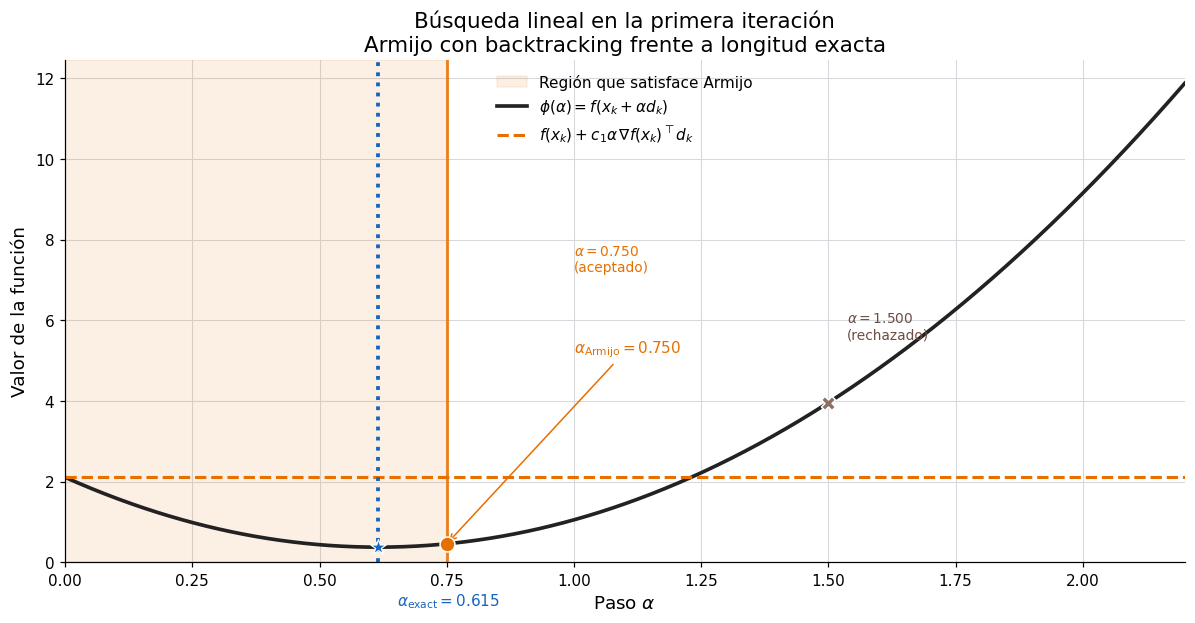

In [17]:
import argparse
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

# ---------------------------------------------------------------------------
# Figuras
# ---------------------------------------------------------------------------

def configure_style() -> None:
    plt.rcParams.update({
        "font.size": 11,
        "axes.labelsize": 12,
        "axes.titlesize": 14,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "legend.fontsize": 10,
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.axisbelow": True,
    })


def plot_line_search(
    x_current: np.ndarray,
    direction: np.ndarray,
    alpha_armijo: float,
    tested: list[float],
    alpha_exact: float,
    c1: float = C1,
) -> None:
    """
    Dibuja phi(alpha) = f(x_k + alpha d_k), la recta que define el descenso
    suficiente de Armijo, los pasos examinados y el minimizador exacto.
    """
    alpha_plot = np.linspace(0.0, 2.2, 1000)
    phi = line_objective(x_current, direction, alpha_plot)

    f_current = objective(x_current)
    directional_derivative = float(gradient(x_current) @ direction)
    armijo_line = f_current + c1 * alpha_plot * directional_derivative

    fig, ax = plt.subplots(figsize=(11, 5.8))

    # Región que satisface la condición suficiente de Armijo.
    ax.axvspan(
        0.0,
        alpha_armijo,
        color=COLOR_ARMIJO,
        alpha=0.10,
        label="Región que satisface Armijo",
    )

    ax.plot(
        alpha_plot,
        phi,
        color="#222222",
        linewidth=2.4,
        label=r"$\phi(\alpha)=f(x_k+\alpha d_k)$",
    )

    ax.plot(
        alpha_plot,
        armijo_line,
        color=COLOR_ARMIJO,
        linestyle="--",
        linewidth=2.0,
        label=r"$f(x_k)+c_1\alpha\,\nabla f(x_k)^\top d_k$",
    )

    # Pasos examinados por el backtracking: rechazados y aceptado.
    for alpha in tested:
        accepted = np.isclose(alpha, alpha_armijo)
        value = objective(x_current + alpha * direction)

        ax.scatter(
            alpha,
            value,
            s=95 if accepted else 85,
            marker="o" if accepted else "X",
            color=COLOR_ARMIJO if accepted else "#8D6E63",
            edgecolor="white",
            linewidth=1.0,
            zorder=5,
        )

        ax.annotate(
            f"$\\alpha={alpha:.3f}$"
            + ("\n(aceptado)" if accepted else "\n(rechazado)"),
            xy=(alpha, value),
            xytext=(1.0, 7.2) if accepted else (12, 42),
            textcoords="data" if accepted else "offset points",
            fontsize=9,
            color=COLOR_ARMIJO if accepted else "#6D4C41",
        )

    ax.axvline(alpha_armijo, color=COLOR_ARMIJO, linewidth=2.0, alpha=0.8)

    # Minimizador exacto de phi.
    ax.axvline(alpha_exact, color=COLOR_EXACT, linestyle=":", linewidth=2.5)
    phi_exact = objective(x_current + alpha_exact * direction)

    ax.scatter(
        alpha_exact,
        phi_exact,
        s=110,
        marker="*",
        color=COLOR_EXACT,
        edgecolor="white",
        linewidth=0.8,
        zorder=6,
    )

    ax.annotate(
        f"$\\alpha_{{\\mathrm{{exact}}}}={alpha_exact:.3f}$",
        xy=(alpha_exact, phi_exact),
        xytext=(12, -38),
        textcoords="offset points",
        fontsize=10,
        color=COLOR_EXACT,
        fontweight="bold",
    )

    ax.annotate(
        f"$\\alpha_{{\\mathrm{{Armijo}}}}={alpha_armijo:.3f}$",
        xy=(
            alpha_armijo,
            objective(x_current + alpha_armijo * direction),
        ),
        xytext=(1.0, 5.2),
        textcoords="data",
        fontsize=10,
        color=COLOR_ARMIJO,
        fontweight="bold",
        arrowprops={"arrowstyle": "->", "color": COLOR_ARMIJO},
    )

    ax.set_xlim(0.0, 2.2)
    ax.set_ylim(bottom=min(0.0, float(phi.min()) * 1.10))
    ax.set_xlabel(r"Paso $\alpha$")
    ax.set_ylabel(r"Valor de la función")
    ax.set_title(
        "Búsqueda lineal en la primera iteración\n"
        "Armijo con backtracking frente a longitud exacta"
    )
    ax.grid(True, color=COLOR_GRID, linewidth=0.7)
    ax.legend(loc="best", frameon=False)

    fig.tight_layout()
    plt.show()


def plot_contours(
    points_armijo: np.ndarray,
    points_exact: np.ndarray,
    direction: np.ndarray,
    alpha_armijo: float,
    alpha_exact: float,
) -> None:
    """
    Dibuja las curvas de nivel de f y las trayectorias completas de ambos
    métodos de steepest descent.
    """
    x_grid = np.linspace(-2.6, 2.4, 500)
    y_grid = np.linspace(-2.3, 1.9, 500)
    xx, yy = np.meshgrid(x_grid, y_grid)

    zz = 0.5 * (
        Q[0, 0] * xx**2
        + 2 * Q[0, 1] * xx * yy
        + Q[1, 1] * yy**2
    )

    # Niveles geométricos positivos: se omiten los valores casi planos.
    levels = np.geomspace(0.08, float(zz.max()), 14)

    fig, ax = plt.subplots(figsize=(9.2, 7))

    contours = ax.contour(
        xx, yy, zz,
        levels=levels,
        colors="#90A4AE",
        linewidths=0.9,
        alpha=0.9,
    )
    ax.clabel(contours, inline=True, fontsize=7, fmt="%.1f")

    ax.plot(
        points_armijo[:, 0], points_armijo[:, 1],
        color=COLOR_ARMIJO,
        linewidth=2.2,
        marker="o",
        markersize=4,
        label="Armijo + backtracking",
    )

    ax.plot(
        points_exact[:, 0], points_exact[:, 1],
        color=COLOR_EXACT,
        linewidth=2.2,
        marker="s",
        markersize=4,
        label="Longitud exacta",
    )

    armijo_point = X0 + alpha_armijo * direction
    exact_point = X0 + alpha_exact * direction

    ax.scatter(
        armijo_point[0], armijo_point[1],
        s=120, color=COLOR_ARMIJO,
        edgecolor="white", linewidth=1.0, zorder=6,
    )
    ax.scatter(
        exact_point[0], exact_point[1],
        s=120, color=COLOR_EXACT,
        edgecolor="white", linewidth=1.0, zorder=6,
    )

    ax.scatter(
        X0[0], X0[1],
        s=140, color=COLOR_CURRENT, marker="D",
        edgecolor="white", linewidth=1.0, zorder=7,
        label=r"Punto inicial $x_0$",
    )
    ax.scatter(
        0.0, 0.0,
        s=180, color=COLOR_OPTIMUM, marker="*",
        edgecolor="white", linewidth=0.8, zorder=7,
        label=r"Óptimo $x^\star=(0,0)$",
    )

    ax.set_xlim(x_grid.min(), x_grid.max())
    ax.set_ylim(y_grid.min(), y_grid.max())
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel(r"$x_1$")
    ax.set_ylabel(r"$x_2$")
    ax.set_title("Trayectorias de steepest descent")
    ax.grid(True, color=COLOR_GRID, linewidth=0.5, alpha=0.7)
    ax.legend(loc="best", frameon=True)

    fig.tight_layout()
    plt.show()


def plot_convergence(
    values_armijo: np.ndarray,
    values_exact: np.ndarray,
) -> None:
    """Compara f(x_k) en función del número de iteración."""
    floor = 1.0e-16

    fig, ax = plt.subplots(figsize=(9.5, 5.5))

    ax.semilogy(
        np.arange(len(values_armijo)),
        np.maximum(values_armijo, floor),
        color=COLOR_ARMIJO,
        linewidth=2.2,
        marker="o",
        markersize=5,
        label="Armijo + backtracking",
    )
    ax.semilogy(
        np.arange(len(values_exact)),
        np.maximum(values_exact, floor),
        color=COLOR_EXACT,
        linewidth=2.2,
        marker="s",
        markersize=5,
        label="Longitud exacta",
    )

    ax.set_xlabel("Iteración")
    ax.set_ylabel(r"$f(x_k)$")
    ax.set_title("Convergencia del valor objetivo")
    ax.grid(True, which="both", color=COLOR_GRID, linewidth=0.7)
    ax.legend(frameon=False)

    fig.tight_layout()
    plt.show()


# ---------------------------------------------------------------------------
# Programa principal - Generación de la Primera Figura
# ---------------------------------------------------------------------------

configure_style()

x_current = X0.copy()
direction = -gradient(x_current)

alpha_armijo, tested = armijo_backtracking(
    x_current,
    direction,
    alpha_initial=ALPHA_INITIAL,
    beta=BETA,
    c1=C1,
)
alpha_exact = exact_line_search(x_current, direction)

# Solo se dibuja la primera figura correspondiente a la búsqueda lineal
plot_line_search(
    x_current=x_current,
    direction=direction,
    alpha_armijo=alpha_armijo,
    tested=tested,
    alpha_exact=alpha_exact,
    c1=C1,
)

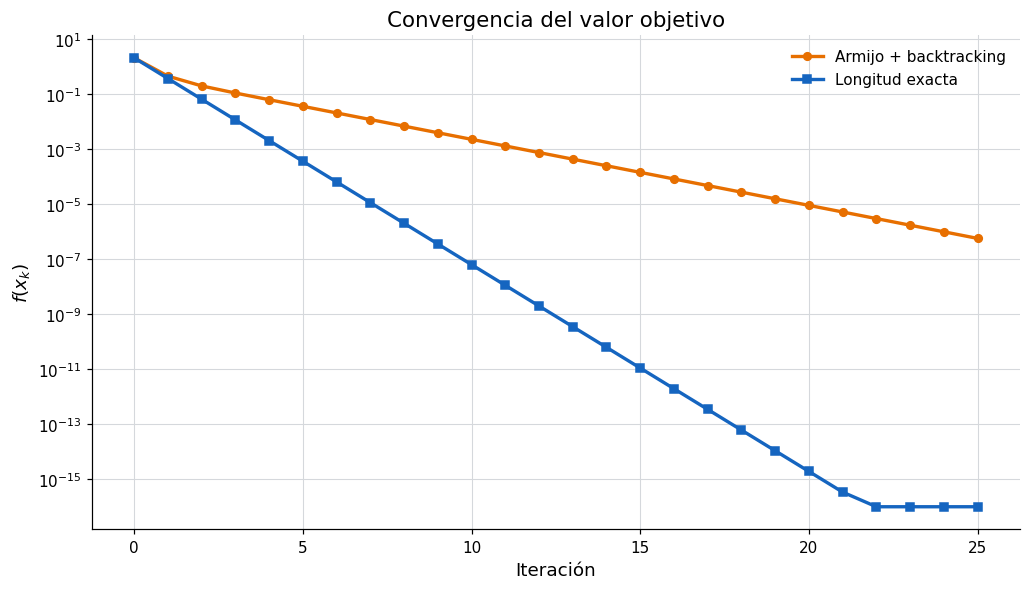

In [18]:
# ---------------------------------------------------------------------------
# Celda 3: Gráfico de Convergencia del Valor Objetivo
# ---------------------------------------------------------------------------

points_armijo, values_armijo, steps_armijo = run_iterations("armijo")
points_exact, values_exact, steps_exact = run_iterations("exact")

plot_convergence(
    values_armijo=values_armijo,
    values_exact=values_exact,
)

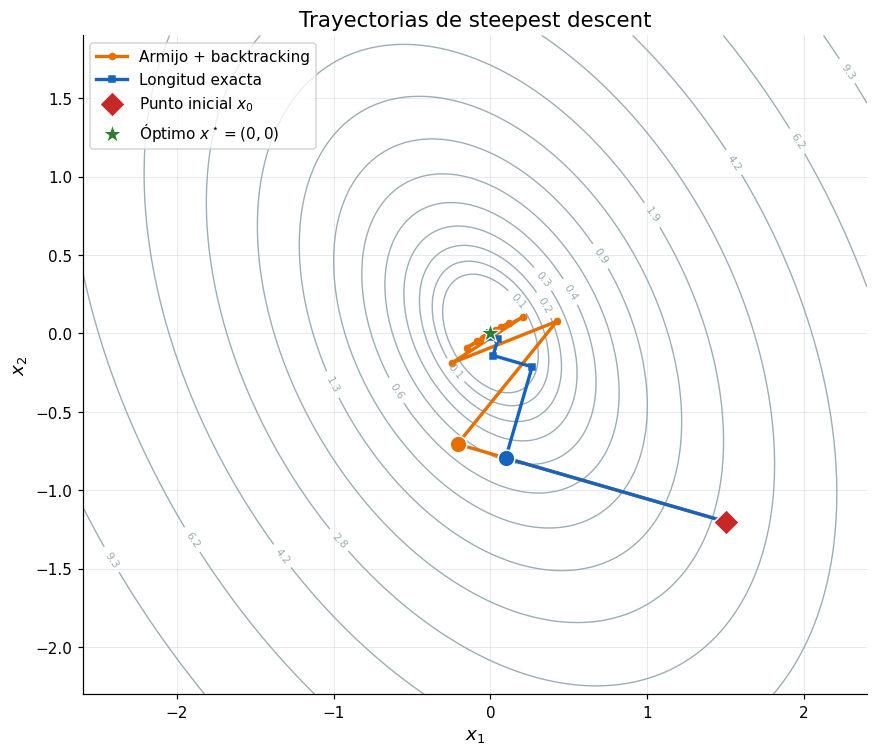

In [20]:
configure_style()

plot_contours(
    points_armijo=points_armijo,
    points_exact=points_exact,
    direction=direction,
    alpha_armijo=alpha_armijo,
    alpha_exact=alpha_exact,
)